## Calculating the band structure of $Si$ and $SiO_2$

Run all cells to calculate the band structures of $Si$ and $SiO_2$ using quantum-espresso based on the tutorials at https://pranabdas.github.io/espresso/

## 1. Load Modules

In [1]:
# Modules + QE setup for the Si / SiO2 band-structure workflow:
#   write pw.x inputs -> run scf + bands -> run bands.x -> plot E(k)
import math, os, re, shutil, subprocess, time, urllib.request   # run QE executables, fetch pseudopotentials
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
QE_BIN = ROOT / "qe" / "bin"                     # native Windows build (see build_qe.sh)
PSEUDO_DIR = ROOT / "pseudo"
RUNS = ROOT / "runs"
RUNS.mkdir(exist_ok=True)

os.environ["PATH"] = str(QE_BIN) + os.pathsep + os.environ["PATH"]   # bundled MinGW DLLs live here too
# One thread is far faster here: this SCF took 2.5 s on 1 thread, about 115 s on 6 and 190 s on 12
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ.setdefault("OMP_STACKSIZE", "256M")   # OpenMP threads overflow the default Windows stack
os.environ.setdefault("ESPRESSO_PSEUDO", str(PSEUDO_DIR))

PW = shutil.which("pw.x.exe", path=str(QE_BIN))
BANDS = shutil.which("bands.x.exe", path=str(QE_BIN))
assert PW and BANDS, f"pw.x / bands.x not found in {QE_BIN}"

def run_qe(exe, inp: Path, out: Path | None = None):
    """Run a QE executable on `inp` inside its folder, write stdout to `out` (default: .in -> .out)."""
    inp = Path(inp)
    out = Path(out) if out else inp.with_suffix(".out")
    with open(inp) as fin, open(out, "w") as fout:
        res = subprocess.run([exe], stdin=fin, stdout=fout, stderr=subprocess.STDOUT, cwd=inp.parent)
    if res.returncode != 0 or "JOB DONE" not in out.read_text(errors="ignore"):
        raise RuntimeError(f"{Path(exe).name} failed on {inp.name} - see {out}")
    return out

CHECKS = []
def check(name, ok, detail=""):
    CHECKS.append((name, bool(ok), detail))
    print(f"[{'PASS' if ok else 'FAIL'}] {name}" + (f" - {detail}" if detail else ""))

print("pw.x   :", PW)
print("bands.x:", BANDS)
print("pseudos:", sorted(p.name for p in PSEUDO_DIR.glob("*.[uU][pP][fF]")))

pw.x   : C:\Users\Caesium\Desktop\qe_exp\qe\bin\pw.x.exe
bands.x: C:\Users\Caesium\Desktop\qe_exp\qe\bin\bands.x.exe
pseudos: ['Si.pz-vbc.UPF', 'Si_r.upf']


## 2. Live Convergence Monitor

`run_live` runs `pw.x` and redraws a plot every 2 seconds, so you can see how close each calculation is to finishing.

- **SCF:** accuracy per iteration against the `conv_thr` target. The percentage is how far accuracy has fallen from its first value towards the target, on a log scale.
- **Bands:** k-points finished out of the total. This needs `verbosity = 'high'`, otherwise `pw.x` doesn't report them.

The time left is an estimate. Stopping the cell also stops `pw.x`.

In [2]:
# Live monitor: pw.x writes to its .out file as it runs, so we re-read that file every
# few seconds and redraw one figure in place.
#   scf   -> distance from conv_thr, per iteration
#   bands -> k-points finished, out of the total
# Time left is an estimate: SCF extrapolates the recent trend, bands uses recent k-point times.
BLUE, INK, MUTED, GRID, TRACK = "#2a78d6", "#0b0b0b", "#52514e", "#e6e5e0", "#f0efec"

def read_progress(text):
    """Pull the convergence numbers out of a pw.x output, finished or not."""
    text = text[:text.rfind("\n") + 1]                 # ignore a half-written last line
    kpts = re.findall(r"Computing kpt #:\s+\d+\s+of\s+\d+\s*\n\s*total cpu time spent up to now is\s+([0-9.]+)", text)
    total = re.findall(r"Computing kpt #:\s+\d+\s+of\s+(\d+)", text)
    return {
        "iteration": len(re.findall(r"iteration #\s*\d+", text)),
        "accuracy": [max(float(a), 1e-30) for a in
                     re.findall(r"estimated scf accuracy\s+<\s+([0-9.]+(?:[Ee][+-]?[0-9]+)?)", text)],
        "energy": [float(e) for e in re.findall(r"total energy\s+=\s+(-?[0-9.]+) Ry", text)],
        "clock": [float(t) for t in re.findall(r"total cpu time spent up to now is\s+([0-9.]+)", text)],
        "k_clock": [float(t) for t in kpts],
        "k_total": int(total[-1]) if total else 0,
        "done": "JOB DONE" in text,
    }

def scf_estimate(p, conv_thr):
    """Return (fraction of the way to conv_thr on a log scale, seconds left or None)."""
    acc = p["accuracy"]
    if p["done"] or (acc and acc[-1] < conv_thr):
        return 1.0, 0.0
    if not acc:
        return 0.0, None
    fraction = math.log(acc[0] / acc[-1]) / math.log(acc[0] / conv_thr)
    fraction = min(max(fraction, 0.0), 0.99)
    if len(acc) < 2 or len(p["clock"]) < 3:
        return fraction, None
    logs = np.log10(acc[-3:])
    slope = np.polyfit(range(len(logs)), logs, 1)[0]
    if slope >= 0:                                     # not improving, so no honest estimate
        return fraction, None
    steps_left = math.ceil((math.log10(conv_thr) - logs[-1]) / slope)
    return fraction, steps_left * float(np.mean(np.diff(p["clock"])[-3:]))

def bands_estimate(p):
    """Return (fraction of k-points finished, seconds left or None)."""
    done, total = len(p["k_clock"]), p["k_total"]
    if p["done"]:
        return 1.0, 0.0
    if not total:
        return 0.0, None
    if done < 2:
        return done / total, None
    return done / total, (total - done) * float(np.mean(np.diff(p["k_clock"])[-10:]))

def as_time(seconds):
    return f"{seconds:.0f} s" if seconds < 90 else f"{seconds / 60:.1f} min"

def style(ax, title, xlabel, ylabel):
    ax.set_title(title, loc="left", fontsize=10, color=INK)
    ax.set_xlabel(xlabel, color=MUTED, fontsize=9)
    ax.set_ylabel(ylabel, color=MUTED, fontsize=9)
    ax.tick_params(colors=MUTED, labelsize=8, length=0)
    ax.grid(True, color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)

def draw_scf(left, right, p, conv_thr):
    acc = p["accuracy"]
    style(left, "SCF accuracy", "Iteration", "Estimated accuracy (Ry)")
    left.set_yscale("log")
    left.set_ylim(conv_thr / 5, 1)
    left.axhline(conv_thr, color=MUTED, linestyle=(0, (5, 4)), linewidth=1)
    left.annotate(f"target {conv_thr:.0e} Ry", (1, conv_thr), xycoords=("axes fraction", "data"),
                  xytext=(0, 4), textcoords="offset points", ha="right", fontsize=8, color=MUTED)
    if acc:
        left.plot(range(1, len(acc) + 1), acc, color=BLUE, linewidth=2, marker="o", markersize=5)
        left.set_ylim(min(min(acc), conv_thr) / 5, max(acc) * 5)
    left.set_xlim(0.5, max(len(acc) + 1.5, 6))
    left.xaxis.get_major_locator().set_params(integer=True)

    style(right, "Energy change per iteration", "Iteration", "|ΔE| (Ry)")
    right.set_yscale("log")
    change = np.abs(np.diff(p["energy"]))
    if change.size:
        right.plot(range(2, change.size + 2), np.maximum(change, 1e-12), color=BLUE,
                   linewidth=2, marker="o", markersize=5)
    right.set_xlim(0.5, max(len(acc) + 1.5, 6))
    right.xaxis.get_major_locator().set_params(integer=True)

def draw_bands(left, right, p):
    clock, total = p["k_clock"], p["k_total"]
    style(left, "k-points finished", "Run time (s)", "k-points")
    if total:
        left.axhline(total, color=MUTED, linestyle=(0, (5, 4)), linewidth=1)
        left.annotate(f"total {total}", (0, total), xycoords=("axes fraction", "data"),
                      xytext=(4, -11), textcoords="offset points", fontsize=8, color=MUTED)
        left.set_ylim(0, total * 1.08)
    if clock:
        left.plot(clock, range(1, len(clock) + 1), color=BLUE, linewidth=2)
    _, left_s = bands_estimate(p)
    if clock and left_s:
        left.plot([clock[-1], clock[-1] + left_s], [len(clock), total], color=BLUE,
                  linewidth=1, linestyle=":")
        left.annotate("projected", (clock[-1] + left_s, total), xytext=(-4, -24),
                      textcoords="offset points", ha="right", fontsize=8, color=MUTED)

    style(right, "Time per k-point", "k-point", "Seconds")
    if len(clock) > 1:
        right.plot(range(2, len(clock) + 1), np.diff(clock), color=BLUE, linewidth=2)
        right.set_ylim(bottom=0)
    right.set_xlim(1, max(total, 2))

def draw(fig, p, calculation, conv_thr, elapsed, finished, failed):
    fig.clf()
    grid = fig.add_gridspec(2, 2, height_ratios=[0.05, 1], hspace=0.42, wspace=0.26,
                            left=0.08, right=0.98, top=0.84, bottom=0.14)
    bar = fig.add_subplot(grid[0, :])
    left, right = fig.add_subplot(grid[1, 0]), fig.add_subplot(grid[1, 1])

    if calculation == "scf":
        fraction, seconds = scf_estimate(p, conv_thr)
        draw_scf(left, right, p, conv_thr)
        detail = f"iteration {p['iteration']}"
        if p["accuracy"]:
            detail += f"  ·  accuracy {p['accuracy'][-1]:.1e} Ry"
    else:
        fraction, seconds = bands_estimate(p)
        draw_bands(left, right, p)
        detail = f"k-point {len(p['k_clock'])} of {p['k_total']}" if p["k_total"] else "starting up"

    if failed:
        state = f"Stopped before finishing after {as_time(elapsed)}"
    elif finished:
        state = f"Finished in {as_time(elapsed)}"
    else:
        left_text = f"about {as_time(seconds)} left" if seconds else "estimating time left"
        state = f"{fraction:.0%}  ·  {left_text}"
    fig.text(0.08, 0.93, f"{calculation.upper()}: {state}", fontsize=12, color=INK, weight="bold")
    fig.text(0.98, 0.93, detail, fontsize=9, color=MUTED, ha="right")

    bar.barh(0, 1, color=TRACK, height=1)
    bar.barh(0, fraction, color=BLUE, height=1)
    bar.set_xlim(0, 1)
    bar.axis("off")

def run_live(exe, inp, out=None, refresh=2.0):
    """Run pw.x on `inp` and redraw a convergence plot while it runs. Returns the exit code."""
    inp = Path(inp)
    out = Path(out) if out else inp.with_suffix(".out")
    settings = inp.read_text()
    calculation = re.search(r"calculation\s*=\s*'(\w+)'", settings).group(1)
    conv_thr = float(re.search(r"conv_thr\s*=\s*([0-9.eE+-]+)", settings).group(1))

    fig = plt.figure(figsize=(10, 4.2), dpi=110, facecolor="#fcfcfb")
    plt.close(fig)                                     # stops a second copy appearing at the end
    handle = display(fig, display_id=True)

    started = time.time()
    def redraw(finished=False, failed=False):
        p = read_progress(out.read_text(errors="ignore") if out.exists() else "")
        draw(fig, p, calculation, conv_thr, time.time() - started, finished, failed)
        handle.update(fig)

    with open(inp) as fin, open(out, "w") as fout:
        proc = subprocess.Popen([exe], stdin=fin, stdout=fout, stderr=subprocess.STDOUT, cwd=inp.parent)
        try:
            while proc.poll() is None:
                redraw()
                time.sleep(refresh)
        except BaseException:                          # e.g. the stop button: don't leave pw.x running
            proc.kill()
            proc.wait()
            redraw(failed=True)
            raise
    ok = proc.returncode == 0 and "JOB DONE" in out.read_text(errors="ignore")
    redraw(finished=ok, failed=not ok)
    return proc.returncode

## 3. Run the SCF Calculation with Smeared Occupations

In [3]:
PSEUDO_DIR.mkdir(exist_ok=True)
upf = PSEUDO_DIR / "Si.pz-vbc.UPF"
RUN = ROOT / "runs" / "bg_silicon_live"
RUN.mkdir(parents=True, exist_ok=True)
INPUT = f'''&CONTROL
  calculation = 'scf',
  restart_mode = 'from_scratch',
  prefix = 'silicon',
  outdir = './tmp/'
  pseudo_dir = '{PSEUDO_DIR.as_posix()}/'
  verbosity = 'high'
/
&SYSTEM
  ibrav = 2,
  celldm(1) = 10.2076,
  nat = 2,
  ntyp = 1,
  ecutwfc = 50,
  ecutrho = 400,
  nbnd = 8,
!  occupations = 'smearing',
!  smearing = 'gaussian',
!  degauss = 0.005
/
&ELECTRONS
  conv_thr = 1e-8,
  mixing_beta = 0.6
/
ATOMIC_SPECIES
  Si 28.086 Si.pz-vbc.UPF
ATOMIC_POSITIONS (alat)
  Si 0.0 0.0 0.0
  Si 0.25 0.25 0.25
K_POINTS (automatic)
  8 8 8 0 0 0
'''
(RUN / "pw.scf.silicon.in").write_text(INPUT)

564

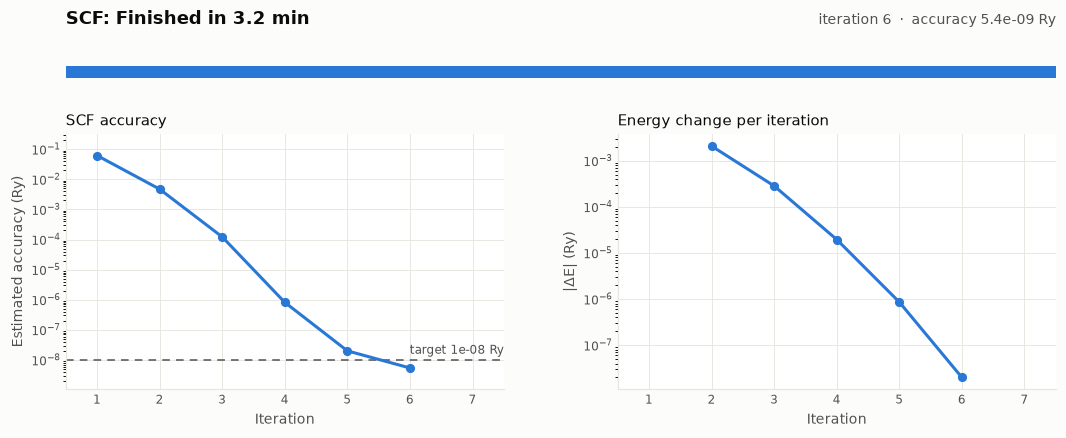

C:\Users\Caesium\AppData\Local\Temp\ipykernel_8292\233680075.py:78: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  left.set_xlim(0.5, max(len(acc) + 1.5, 6))


[PASS] pw.x exit code 0 - code 0
[PASS] JOB DONE - 192.3 s
[PASS] SCF converged
Program PWSCF v.7.6 starts on  5Nov2026 at  0:37:22 


In [5]:
# Equivalent of:  pw.x < pw.scf.silicon.in > pw.scf.silicon.out, with a live convergence plot
t0 = time.time()
returncode = run_live(PW, RUN / "pw.scf.silicon.in")
elapsed = time.time() - t0
OUT = (RUN / "pw.scf.silicon.out").read_text(errors="ignore")

check("pw.x exit code 0", returncode == 0, f"code {returncode}")
check("JOB DONE", "JOB DONE" in OUT, f"{elapsed:.1f} s")
check("SCF converged", "convergence has been achieved" in OUT)
print(re.search(r"Program PWSCF.*", OUT).group(0))

## 4. Run the Band Structure Calculations

In [6]:
BAND = f'''&control
  calculation = 'bands',
  restart_mode = 'from_scratch',
  prefix = 'silicon',
  outdir = './tmp/'
  pseudo_dir = '{PSEUDO_DIR.as_posix()}/'
  verbosity = 'high'
/
&system
  ibrav = 2,
  celldm(1) = 10.2076,
  nat = 2,
  ntyp = 1,
  ecutwfc = 50,
  ecutrho = 400,
  nbnd = 8
 /
&electrons
  conv_thr = 1e-8,
  mixing_beta = 0.6
 /
ATOMIC_SPECIES
  Si 28.086  Si.pz-vbc.UPF
ATOMIC_POSITIONS (alat)
  Si 0.00 0.00 0.00
  Si 0.25 0.25 0.25
K_POINTS {{crystal_b}}
5
  0.0000 0.5000 0.0000 20  !L
  0.0000 0.0000 0.0000 30  !G
  -0.500 0.0000 -0.500 10  !X
  -0.375 0.2500 -0.375 30  !U
  0.0000 0.0000 0.0000 20  !G
'''
(RUN / "pw.scf.bg_silicon.in").write_text(BAND)

635

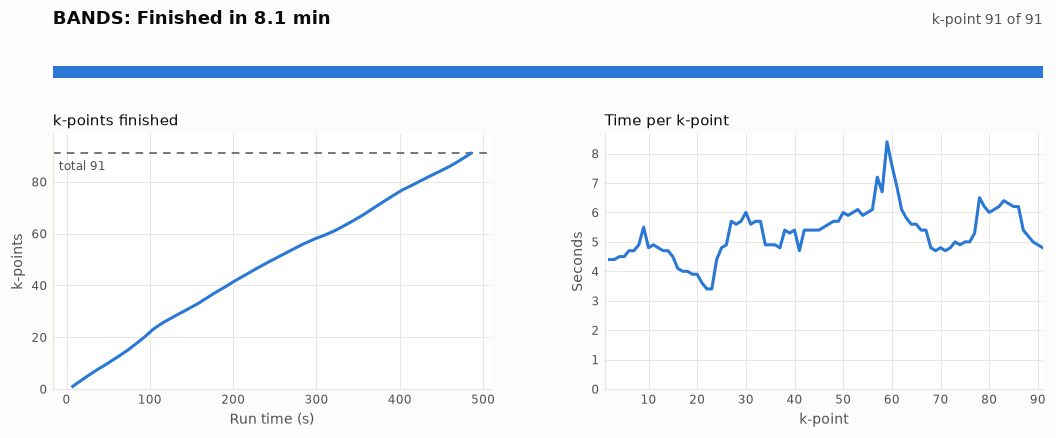

[PASS] pw.x exit code 0 - code 0
[PASS] JOB DONE - 487.4 s
[PASS] Bands finished
Program PWSCF v.7.6 starts on  5Nov2026 at  0:41:25 


In [7]:
# Equivalent of:  pw.x < pw.scf.bg_silicon.in > pw.scf.bg_silicon.out, with a live progress plot
t0 = time.time()
returncode = run_live(PW, RUN / "pw.scf.bg_silicon.in")
elapsed = time.time() - t0
OUT = (RUN / "pw.scf.bg_silicon.out").read_text(errors="ignore")

check("pw.x exit code 0", returncode == 0, f"code {returncode}")
check("JOB DONE", "JOB DONE" in OUT, f"{elapsed:.1f} s")
check("Bands finished", "End of band structure calculation" in OUT)
print(re.search(r"Program PWSCF.*", OUT).group(0))

## 5. Post-Processing and Plot

In [8]:
POST = f'''&BANDS
  prefix = 'silicon'
  outdir = './tmp/'
  filband = 'si_bands.dat'
/
'''
(RUN / "pw.scf.pp_silicon.in").write_text(POST)

# Equivalent of:  bands.x < pw.scf.pp_silicon.in > pw.scf.pp_silicon.out
run_qe(BANDS, RUN / "pw.scf.pp_silicon.in")
check("bands.x wrote data", (RUN / "si_bands.dat.gnu").exists())

[PASS] bands.x wrote data


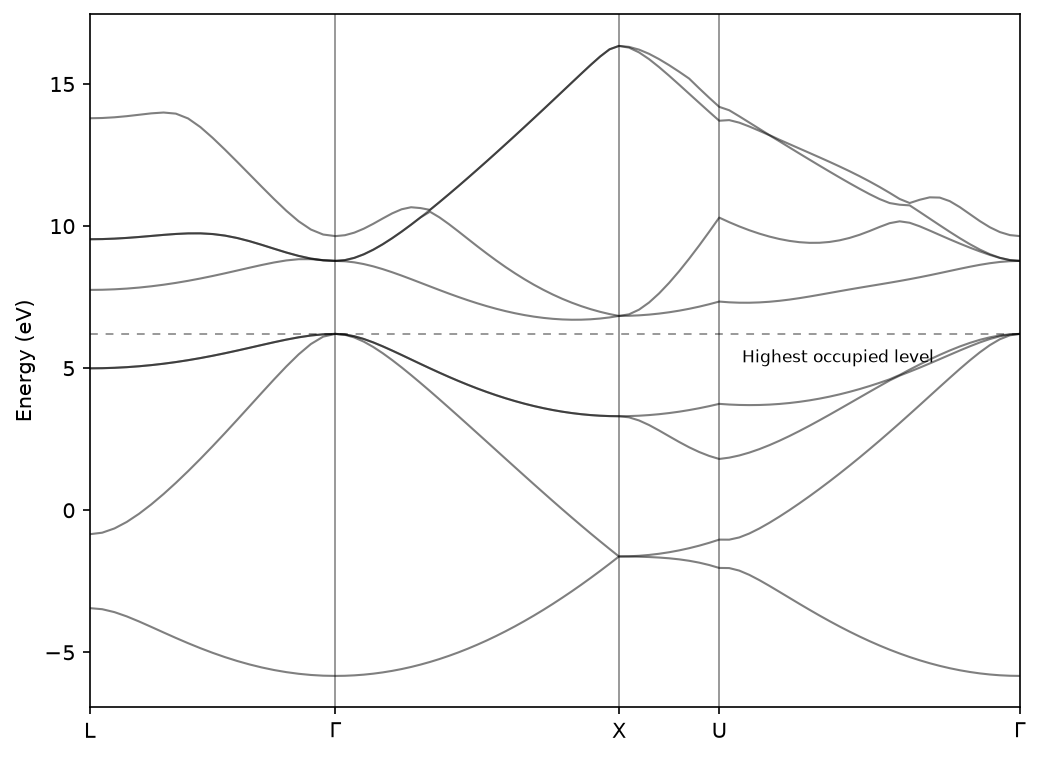

In [9]:
import matplotlib.pyplot as plt
from matplotlib import rcParamsDefault
import numpy as np
%matplotlib inline

plt.rcParams["figure.dpi"]=150
plt.rcParams["figure.facecolor"]="white"
plt.rcParams["figure.figsize"]=(8, 6)

# load data
data = np.loadtxt(RUN / 'si_bands.dat.gnu')

k = np.unique(data[:, 0])
bands = np.reshape(data[:, 1], (-1, len(k)))

for band in range(len(bands)):
    plt.plot(k, bands[band, :], linewidth=1, alpha=0.5, color='k')
plt.xlim(min(k), max(k))

# Highest occupied level, read from this run's SCF output
SCF_OUT = (RUN / "pw.scf.silicon.out").read_text(errors="ignore")
vbm = float(re.search(r"highest occupied(?:, lowest unoccupied)? level \(ev\):\s+(-?[0-9.]+)", SCF_OUT).group(1))
plt.axhline(vbm, linestyle=(0, (5, 5)), linewidth=0.75, color='k', alpha=0.5)
# High symmetry k-points (check bands_pp.out)
plt.axvline(0.8660, linewidth=0.75, color='k', alpha=0.5)
plt.axvline(1.8660, linewidth=0.75, color='k', alpha=0.5)
plt.axvline(2.2196, linewidth=0.75, color='k', alpha=0.5)
# text labels
plt.xticks(ticks= [0, 0.8660, 1.8660, 2.2196, 3.2802], \
           labels=['L', r'$\Gamma$', 'X', 'U', r'$\Gamma$'])
plt.ylabel("Energy (eV)")
plt.text(2.3, vbm - 1.0, 'Highest occupied level', fontsize='small')
plt.show()